# Day 11 - Final held-out test evaluation

This records the **first and only final test-set evaluation** after Day 10 froze all development decisions. XGBoost, 42 demographic-free predictors, raw probabilities and diagnostic threshold **0.50** remain unchanged.

The authorized evaluation pipeline fits once on the exact safe pre-test history and makes one TEST `predict_proba` call. An ignored local receipt/checkpoint preserves that original vector. **Rerunning this notebook loads the same saved results without refitting or rescoring**. Recomputing aggregate summaries or bootstrap resamples does not produce new model predictions.

No tuning, new predictors, calibration fitting, new threshold selection or policy changes are allowed after test inspection. Player-level checkpoints remain under ignored `data/processed/`; public outputs contain aggregate evidence only.

In [1]:
from pathlib import Path
import sys
import json
import matplotlib
matplotlib.use('Agg')
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT = Path.cwd()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'src/final_test.py').is_file()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.final_test import (
    execute_or_load, build_aggregate_results, validate_frozen_policy, sha256,
)
from src.final_test_reporting import export_final_report, final_report

def show_figure(name):
    display(Image(filename=str(ROOT / 'reports/figures' / name)))


## 1. Verify the frozen specification before test evaluation

Read the Day 10 JSON specification and validate the exact estimator parameters, raw predictor list, removed demographics, raw calibration policy, 0.50 diagnostic threshold, 30/60-day windows, capacities and refit/test dates. The local pipeline and processed panel must match the recorded Day 10 fingerprints.

Target: no positive-bet day during (S,S+60]. This is extended inactivity, not guaranteed permanent departure. No test outcomes are used to choose a model or policy.

In [2]:
spec = json.loads((ROOT / 'reports/final_model_specification.json').read_text())
validate_frozen_policy(spec)
display(pd.DataFrame([spec['estimator_parameters']]))
display(pd.DataFrame({'frozen_predictor': spec['predictors']}))
print('42 numerical predictors; demographics and metadata excluded; raw scores; diagnostic 0.50.')

,objective,base_score,booster,callbacks,colsample_bylevel,colsample_bynode,colsample_bytree,device,early_stopping_rounds,enable_categorical,...,num_parallel_tree,random_state,reg_alpha,reg_lambda,sampling_method,scale_pos_weight,subsample,tree_method,validate_parameters,verbosity
0,binary:logistic,None,None,None,None,None,0.9,None,None,True,...,None,42,0.1,10,None,None,0.8,hist,None,None


,frozen_predictor
0,active_days_30d
1,bets_30d
2,active_days_14d
3,bets_14d
4,active_days_7d
5,bets_7d
6,avg_bets_per_active_day_30d
7,avg_bets_per_active_day_7d
8,days_since_last_active_bet
9,max_gap_between_active_days_30d


42 numerical predictors; demographics and metadata excluded; raw scores; diagnostic 0.50.


## 2. Execute the frozen final refit and one test prediction, or replay its checkpoint

The entry point verifies the original 18,472 x 48 panel, binary target, unique UserID-snapshot keys and frozen predictor availability.

Final refit: every monthly snapshot from **2005-03-31 through 2006-05-31**, including January/February 2006. Expected 14,242 observations, 3,651 players and 35.9009% inactivity. June/July are excluded. Every label horizon must end before **2006-08-02**; May 31 + 60 days = July 30.

TEST: exactly **2006-08-31, 2006-09-30, 2006-10-31, 2006-11-30**. Expected 2,838 observations, 1,455 players and approximately 34.07% inactivity.

Preprocessing is fitted only during the one final-refit pipeline fit: numerical median imputation with missing indicators, no scaling, dense output. The fitted model is saved before the one test probability call. An incomplete prior evaluation causes a refusal to silently refit/rescore; completed checkpoints are verified and replayed. No calibrator is called or fitted.

In [3]:
raw = execute_or_load(ROOT)
display(pd.DataFrame([raw['refit_summary']]))
display(pd.DataFrame([raw['test_summary']]))
assert raw['fit_calls'] == 1 and raw['test_probability_calls'] == 1
assert raw['threshold'] == .50 and raw['calibration'] == 'raw'
assert np.isfinite(raw['probabilities']).all()
assert ((raw['probabilities'] >= 0) & (raw['probabilities'] <= 1)).all()
print('One saved model fit; one saved TEST probability vector; model artifact fingerprint verified.')

Reusing the one saved TEST probability vector; no model fit or prediction.


,start,end,observations,unique_players,churn_rate,last_outcome_date
0,2005-03-31,2006-05-31,14242,3651,0.359009,2006-07-30


,observations,unique_players,churn_prevalence,start,end
0,2838,1455,0.340733,2006-08-31,2006-11-30


One saved model fit; one saved TEST probability vector; model artifact fingerprint verified.


## 3. Aggregate metrics and whole-player uncertainty

Use the original saved raw probability vector for all summaries. Binary predictions are derived with p >= 0.50, never a second estimator prediction call. Accuracy is supplementary to discrimination and probability quality.

Bootstrap: 1,000 replicates, seed 42, whole UserID clusters sampled with replacement, retaining all snapshots and cluster multiplicity. Recompute rank capacities and prevalence per replicate. Report valid counts per metric; undefined single-class statistics are omitted only for the affected metric. These intervals are conditional on the frozen fitted model, not training/selection uncertainty.

In [4]:
analysis = build_aggregate_results(raw, ROOT)
display(analysis['metrics'].T.rename(columns={0: 'test_value'}))
display(analysis['intervals'])

,test_value
roc_auc,0.748954
average_precision,0.551004
log_loss,0.545688
brier_score,0.186973
accuracy,0.696970
balanced_accuracy,0.645013
precision,0.564848
recall,0.481903
f1,0.520089
specificity,0.808124


,metric,estimate,bootstrap_mean,ci95_low,ci95_high,valid_replicates,undefined_replicates,requested_replicates,random_state
0,roc_auc,0.748954,0.748706,0.730040,0.767841,1000,0,1000,42
1,average_precision,0.551004,0.552031,0.517576,0.586999,1000,0,1000,42
2,brier_score,0.186973,0.187107,0.180521,0.194018,1000,0,1000,42
3,precision,0.564848,0.565008,0.530098,0.600709,1000,0,1000,42
4,recall,0.481903,0.481815,0.451438,0.512001,1000,0,1000,42
5,f1,0.520089,0.519949,0.492183,0.546057,1000,0,1000,42
6,lift_at_top10pct,1.767110,1.765133,1.598260,1.924276,1000,0,1000,42
7,recall_at_top10pct,0.176836,0.176795,0.159916,0.192588,1000,0,1000,42
8,lift_at_top20pct,1.725775,1.732001,1.623206,1.842778,1000,0,1000,42
9,recall_at_top20pct,0.345398,0.346649,0.324985,0.368815,1000,0,1000,42


## 4. Fixed-budget targeting and frozen risk bands

Use unchanged capacities 5/10/15/20/25/30%, ceil(n*f) selected observations and stable original-panel input-order ties. These are player-snapshot counts rather than deduplicated recipients.

Risk bands use test ranking only: bottom 50%, 50th-80th, 80th-90th, top 10%. Descending-rank cuts ceil(n*.1), ceil(n*.2), ceil(n*.5), n produce disjoint bands. Test labels are used only to summarize outcomes after assignment. These bands are prioritization tools, not regulatory categories or new decision thresholds.

In [5]:
display(analysis['targeting'])
display(analysis['risk_bands'])

,target_fraction,selected_observations,actual_fraction,churn_observations_captured,precision,recall,lift
0,0.05,142,0.050035,80,0.563380,0.082730,1.653437
1,0.10,284,0.100070,171,0.602113,0.176836,1.767110
2,0.15,426,0.150106,258,0.605634,0.266805,1.777444
3,0.20,568,0.200141,334,0.588028,0.345398,1.725775
4,0.25,710,0.250176,416,0.585915,0.430196,1.719574
5,0.30,852,0.300211,479,0.562207,0.495346,1.649992


,band,observations,actual_fraction,average_predicted_risk,actual_churn_rate,lift
0,Very high risk (top 10%),284,0.100070,0.612180,0.602113,1.767110
1,High risk (80th-90th),284,0.100070,0.558605,0.573944,1.684439
2,Medium risk (50th-80th),851,0.299859,0.468183,0.460635,1.351893
3,Low risk (bottom 50%),1419,0.500000,0.181147,0.169838,0.498449


## 5. Validation comparison and monthly monitoring

Compare the FINAL demographic-free variant's Day 10 validation evidence, not the earlier full-feature model. The final test model has the frozen settings refitted on more safe history; differences mix temporal/population change with that planned refit. Classification of stability is descriptive, not a new pass/fail rule.

Monthly results are descriptive monitoring only; do not tune on individual test months. ROC-AUC requires both classes. Each monthly top-10% group contains 67-78 observations; it is not used to select a different capacity.

In [6]:
display(analysis['comparison'])
display(analysis['monthly'])

,metric,frozen_validation,final_test,test_minus_validation
0,roc_auc,0.744785,0.748954,0.004169
1,average_precision,0.565764,0.551004,-0.014760
2,brier_score,0.190772,0.186973,-0.003800
3,lift_at_top10pct,1.793262,1.767110,-0.026152
4,recall_at_top10pct,0.179819,0.176836,-0.002983
5,lift_at_top20pct,1.700386,1.725775,0.025389
6,recall_at_top20pct,0.340233,0.345398,0.005165


,snapshot_date,observations,unique_players,churn_prevalence,mean_predicted_risk,roc_auc,average_precision,brier_score,lift_at_top10pct,targeted_top10pct
0,2006-08-31,773,773,0.367400,0.356764,0.733147,0.566076,0.197025,1.640078,78
1,2006-09-30,709,709,0.328632,0.340287,0.773037,0.569036,0.177618,1.885752,71
2,2006-10-31,667,667,0.304348,0.347600,0.742053,0.506405,0.182922,1.863539,67
3,2006-11-30,689,689,0.358491,0.347000,0.750362,0.566271,0.189243,1.697941,69


## 6. Raw calibration and score distribution

Calibration uses the same ten equal-width bins as Day 10, [0,.1), ... [.9,1]. ECE = sum(n_bin/n * abs(mean score - observed frequency)); empty bins contribute zero. No calibration model is fitted on TEST, and no decision to switch sigmoid/isotonic is reopened.

Display score distributions by actual outcome honestly, retaining the already frozen 0.50 diagnostic marker without selecting new cutoffs.

In [7]:
display(analysis['metrics'][['mean_predicted_probability', 'observed_churn_prevalence', 'brier_score', 'log_loss', 'ece']])
display(analysis['calibration'])

,mean_predicted_probability,observed_churn_prevalence,brier_score,log_loss,ece
0,0.348123,0.340733,0.186973,0.545688,0.015567


,bin,lower,upper,observations,mean_probability,observed_prevalence
0,0,0.0,0.1,499,0.045732,0.050100
1,1,0.1,0.2,283,0.148302,0.144876
2,2,0.2,0.3,292,0.253740,0.222603
3,3,0.3,0.4,415,0.350716,0.320482
4,4,0.4,0.5,524,0.452944,0.452290
5,5,0.5,0.6,649,0.548346,0.562404
6,6,0.6,0.7,175,0.626429,0.571429
7,7,0.7,0.8,1,0.701113,1.000000
8,8,0.8,0.9,0,NaN,NaN
9,9,0.9,1.0,0,NaN,NaN


## 7. Export aggregate evidence, figures and model card

Save the required five aggregate CSVs, calibration/comparison tables, final test report, model card and audit metadata. Figures use matplotlib. Only the ignored checkpoint retains player IDs, labels and probabilities; nothing at that grain is written under `reports/`.

`models/final_xgboost_churn_model.joblib` is Git-ignored. Existing Day 10 specifications and development model artifacts remain unchanged.

In [8]:
export_final_report(analysis)
report = final_report(analysis)
def show_section(title):
    text = report.split('## ' + title + '\n', 1)[1].split('\n## ', 1)[0]
    display(Markdown(text))
print('Aggregate reports, seven figures, model card and audit metadata exported.')

Aggregate reports, seven figures, model card and audit metadata exported.


## 8. Discrimination and fixed diagnostic threshold

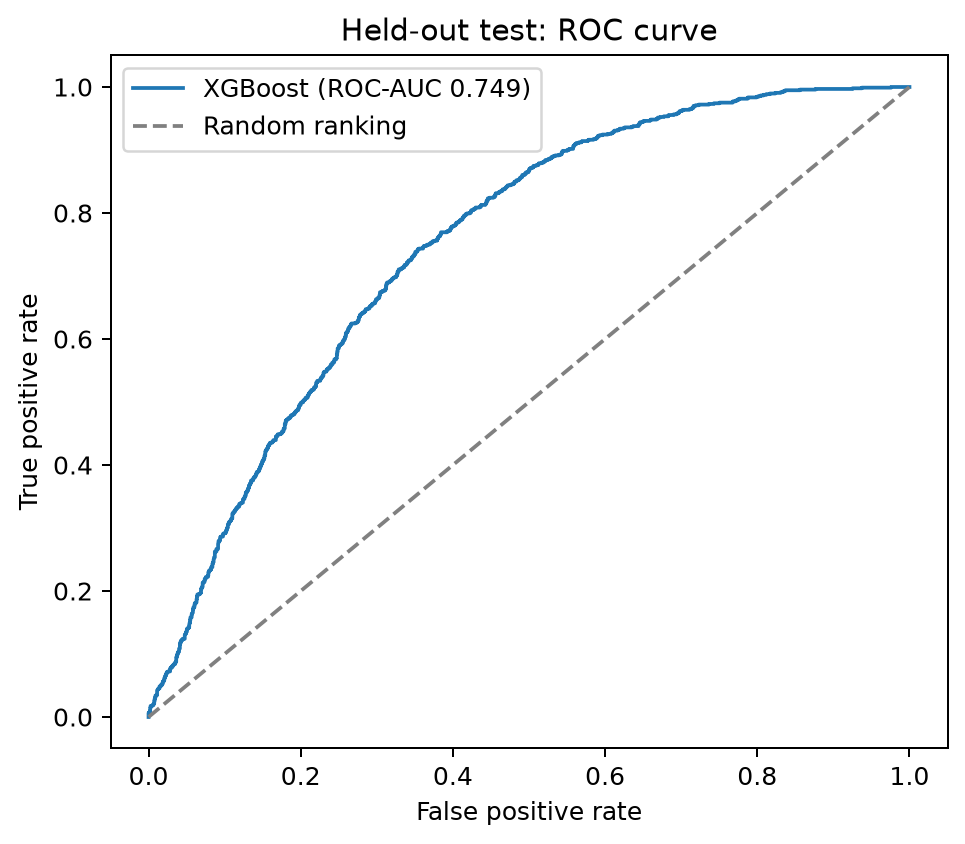

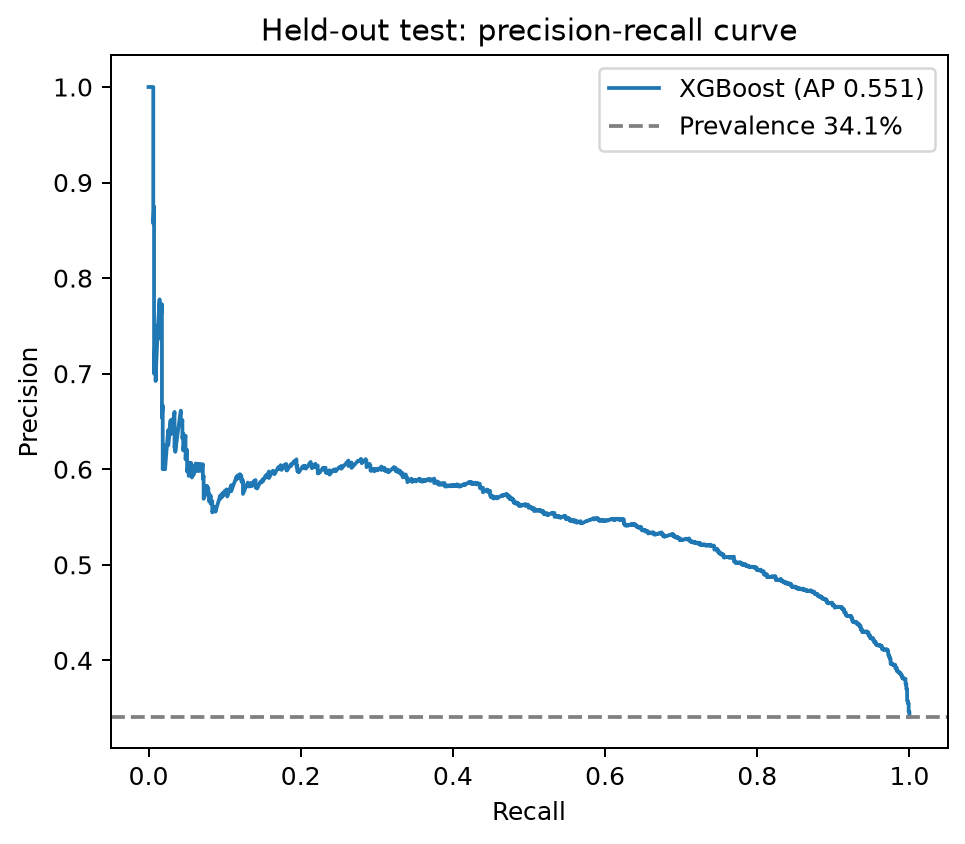

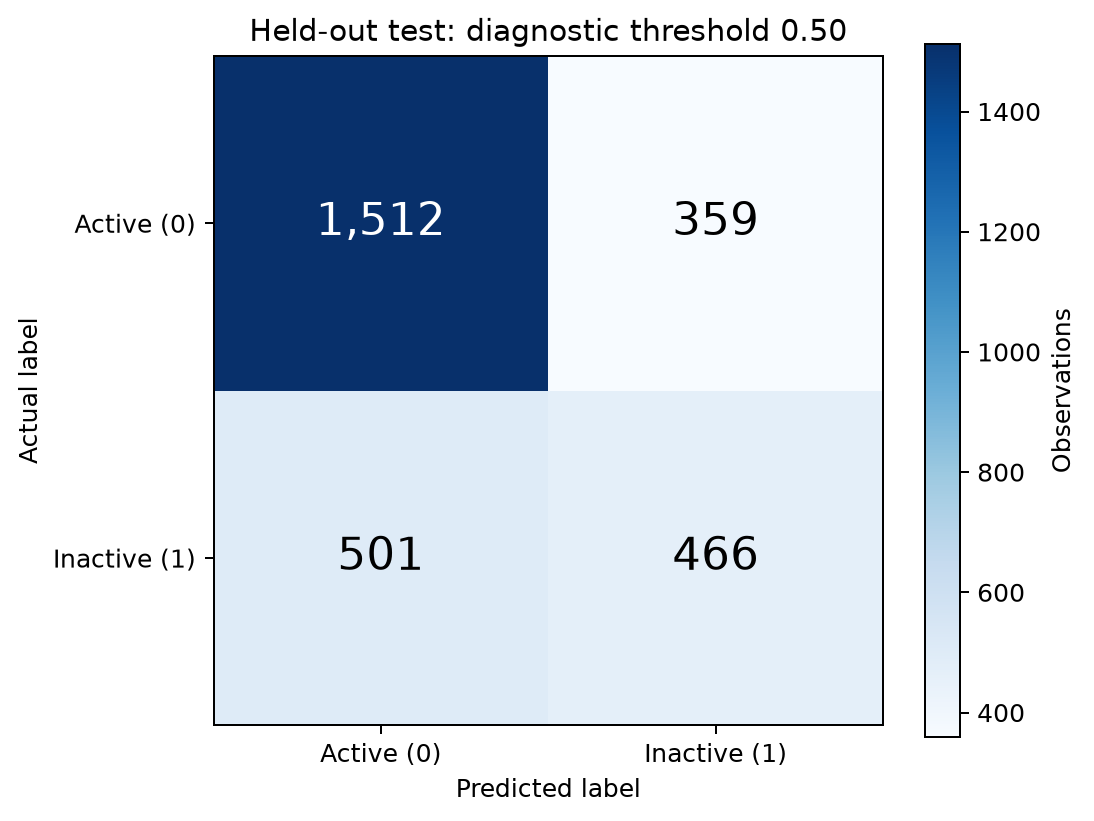

In [9]:
show_figure('final_test_roc_curve.png')
show_figure('final_test_pr_curve.png')
show_figure('final_test_confusion_matrix.png')

## 9. Capacity targeting, risk bands and calibration

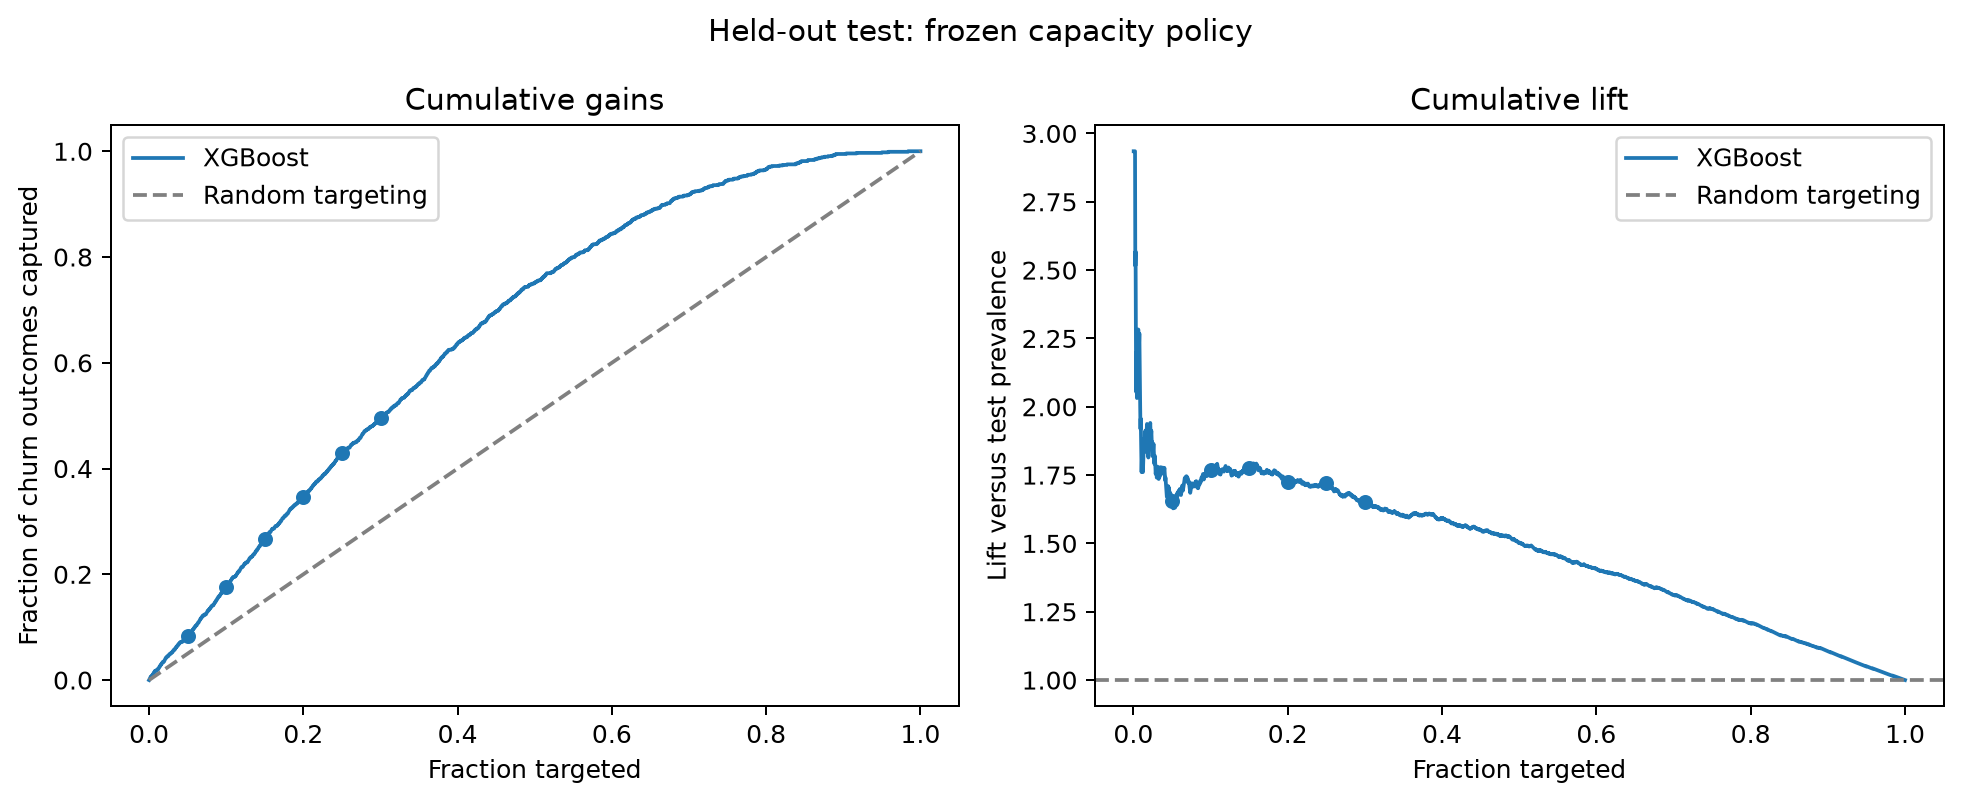

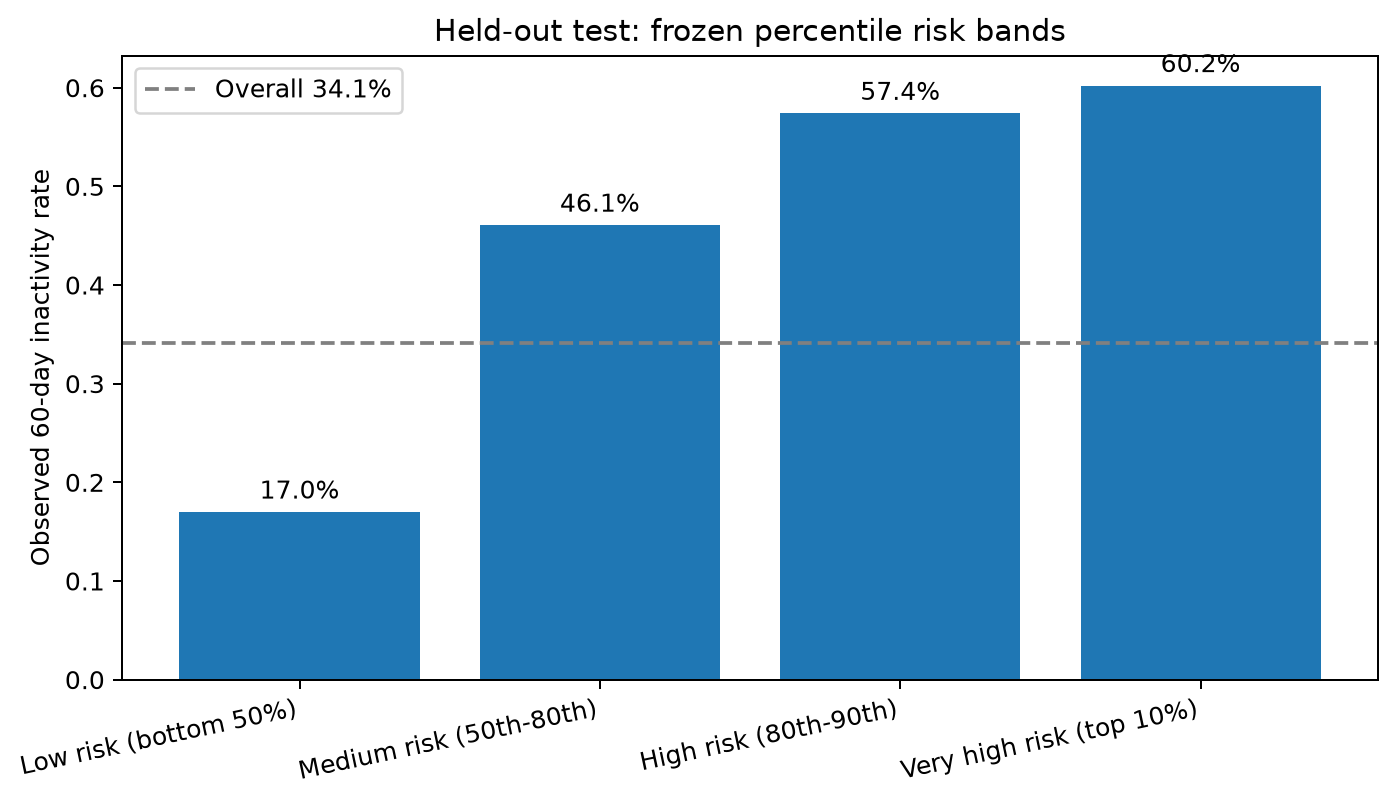

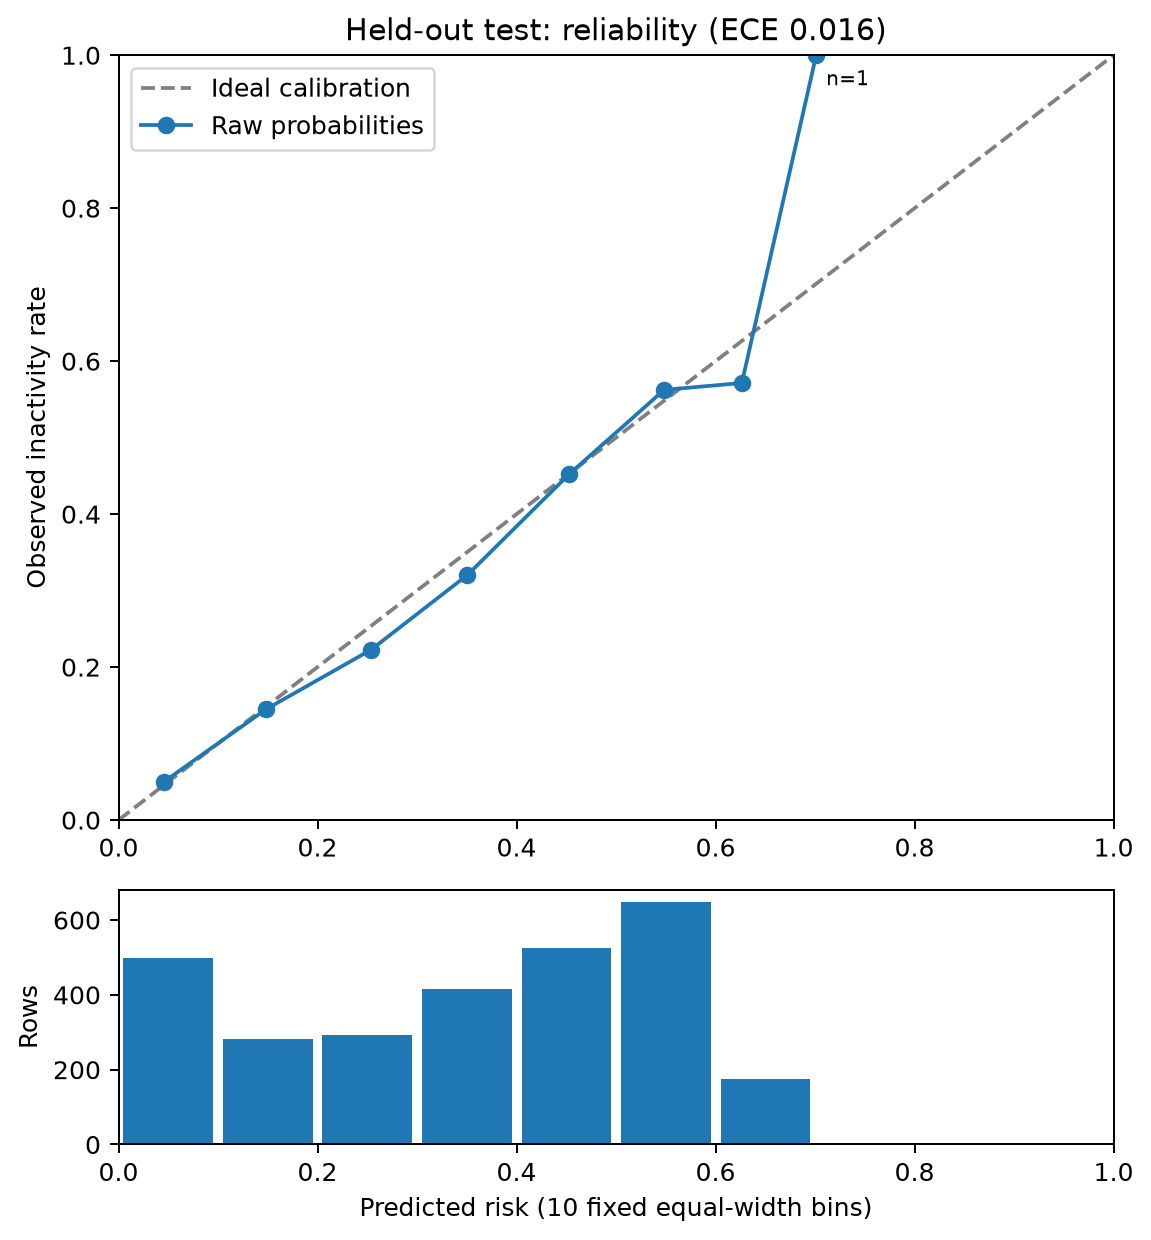

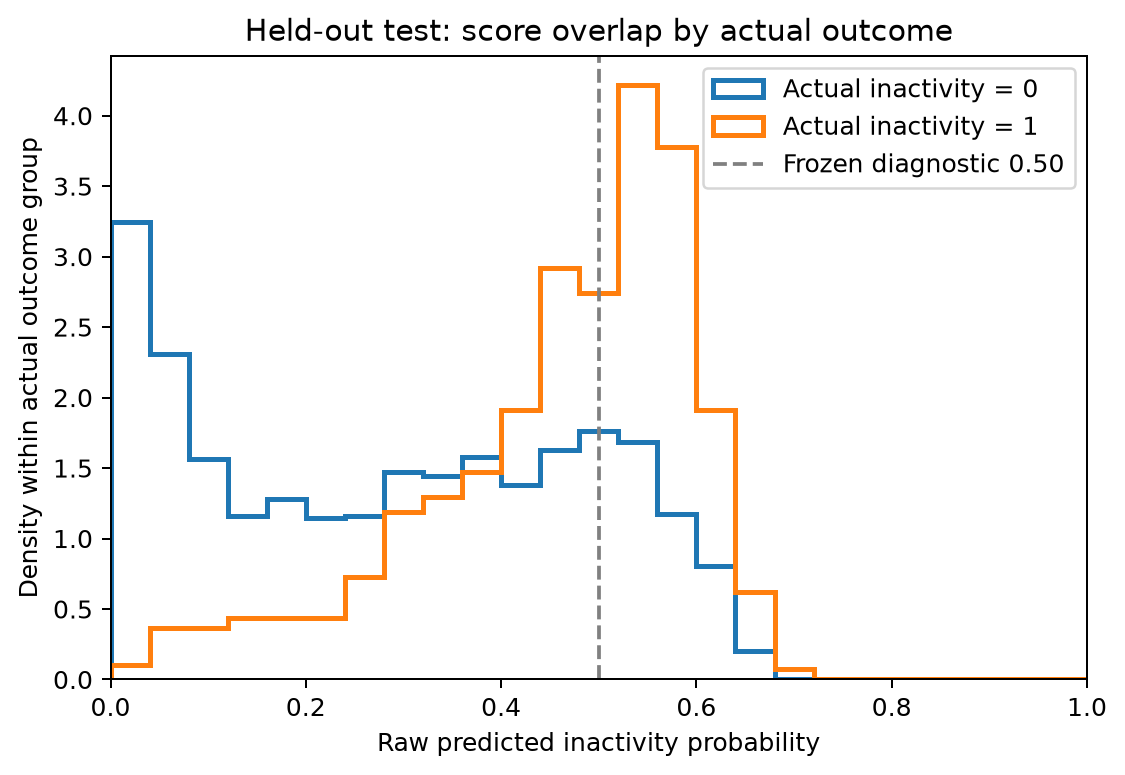

In [10]:
show_figure('final_test_lift_curve.png')
show_figure('final_test_risk_bands.png')
show_figure('final_test_calibration.png')
show_figure('final_test_probability_distribution.png')

## 10. Final generalization interpretation

In [11]:
show_section('F. Validation versus test generalization')
show_section('I. Raw test calibration and score overlap')
show_section('J. Monthly descriptive stability')


| metric | frozen_validation | final_test | test_minus_validation |
| --- | --- | --- | --- |
| roc_auc | 0.744785 | 0.748954 | 0.004169 |
| average_precision | 0.565764 | 0.551004 | -0.014760 |
| brier_score | 0.190772 | 0.186973 | -0.003800 |
| lift_at_top10pct | 1.793262 | 1.767110 | -0.026152 |
| recall_at_top10pct | 0.179819 | 0.176836 | -0.002983 |
| lift_at_top20pct | 1.700386 | 1.725775 | 0.025389 |
| recall_at_top20pct | 0.340233 | 0.345398 | 0.005165 |

**Broadly stable**, descriptively rather than as a pass/fail verdict. Test ROC-AUC improves by 0.0042 and Brier improves by 0.0038; average precision declines by 0.0148. Top-10% targeting is slightly weaker, while top-20% targeting is slightly stronger. Test prevalence is lower than validation (34.07% versus 35.39%), affecting precision and average precision; that does not fully explain or remove the observed AP decline. The test model was refitted on more safe history, so the comparison mixes population/time change with the planned refit. No inferential validation-versus-test difference interval or new pass/fail threshold is claimed, and the selection is not reconsidered.



Mean predicted probability **34.8123%**, observed inactivity **34.0733%**: mean overprediction **0.739 percentage points**. Brier **0.186973**, log loss **0.545688**, ECE **0.015567**.

ECE uses the same ten fixed equal-width bins as Day 10: [0,.1), ... [.9,1], including 1.0 in the last bin. ECE = sum(n_bin/n * abs(mean probability - observed frequency)); empty bins contribute zero. The reliability figure includes bin counts and marks sparse bins. No calibration model, slope map or test-label-derived mapping was fitted; raw probabilities remain frozen.

The class-conditional density plot shows substantial overlap: both active and inactive outcomes occur on each side of 0.50. The false positives and false negatives in the confusion matrix demonstrate that these scores cannot deterministically identify an individual outcome. No additional cutoff was selected from the distribution plot.



| snapshot_date | observations | unique_players | churn_prevalence | mean_predicted_risk | roc_auc | average_precision | brier_score | lift_at_top10pct | targeted_top10pct |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 2006-08-31 | 773 | 773 | 0.367400 | 0.356764 | 0.733147 | 0.566076 | 0.197025 | 1.640078 | 78 |
| 2006-09-30 | 709 | 709 | 0.328632 | 0.340287 | 0.773037 | 0.569036 | 0.177618 | 1.885752 | 71 |
| 2006-10-31 | 667 | 667 | 0.304348 | 0.347600 | 0.742053 | 0.506405 | 0.182922 | 1.863539 | 67 |
| 2006-11-30 | 689 | 689 | 0.358491 | 0.347000 | 0.750362 | 0.566271 | 0.189243 | 1.697941 | 69 |

September has the strongest ROC-AUC (0.7730); August the weakest (0.7331). October has the lowest observed prevalence (30.43%) and average precision (0.5064); predicted mean risk remains approximately 34-36% across months. Top-10% lift ranges from 1.6401 to 1.8858, based on 67-78 selected rows per month. Each monthly snapshot contains one row per player, but players repeat across months. These descriptive differences have no month-specific uncertainty adjustment and do not justify post-test tuning.


## 11. Verification

Tests cover final-refit/test date membership, June/July exclusion, label/feature separation, exact parameters/predictors, removed demographics/metadata, raw scores, 0.50 threshold, finite preprocessing, bounded predictions, one-call synthetic spies, cluster sampling and receipt/cache guards. After evaluation, tests reproduce aggregate metrics directly from the saved vector without scoring the real model.

Run from the root:

```powershell
.\venv\Scripts\python.exe -m unittest discover -s tests -v
```

No post-test tuning is permitted.

In [12]:
metadata = json.loads((ROOT / 'reports/final_test_run_metadata.json').read_text())
assert metadata['model_fit_calls'] == 1
assert metadata['test_predict_proba_calls'] == 1
assert metadata['calibration'] == 'raw' and metadata['diagnostic_threshold'] == .50
assert metadata['demographics_retained'] is False
assert metadata['post_test_model_or_policy_changes'] is False
assert metadata['player_level_predictions_exported'] is False
assert sha256(ROOT / 'reports/final_model_specification.json') == raw['fingerprint']['specification_sha256']
assert sha256(ROOT / 'models/final_xgboost_churn_model.joblib') == raw['model_sha256']
assert analysis['intervals'].valid_replicates.eq(1000).all()
print('Frozen specification unchanged; one saved refit and one saved test prediction; all 1,000 bootstrap draws valid.')

Frozen specification unchanged; one saved refit and one saved test prediction; all 1,000 bootstrap draws valid.


## 12. Final result and governance

In [13]:
show_section('D. Main test metrics')
show_section('E. Whole-player cluster-bootstrap uncertainty')
show_section('G. Fixed-budget targeting')
show_section('H. Frozen percentile risk bands')
show_section('K. Limitations and final governance')


| metric | value |
| --- | --- |
| roc_auc | 0.748954 |
| average_precision | 0.551004 |
| log_loss | 0.545688 |
| brier_score | 0.186973 |
| accuracy | 0.696970 |
| balanced_accuracy | 0.645013 |
| precision | 0.564848 |
| recall | 0.481903 |
| f1 | 0.520089 |
| specificity | 0.808124 |
| true_positives | 466.000000 |
| false_positives | 359.000000 |
| true_negatives | 1512.000000 |
| false_negatives | 501.000000 |
| predicted_positives | 825.000000 |
| recall_at_top10pct | 0.176836 |
| precision_at_top10pct | 0.602113 |
| lift_at_top10pct | 1.767110 |
| recall_at_top20pct | 0.345398 |
| precision_at_top20pct | 0.588028 |
| lift_at_top20pct | 1.725775 |
| threshold | 0.500000 |
| mean_predicted_probability | 0.348123 |
| observed_churn_prevalence | 0.340733 |
| ece | 0.015567 |

ROC-AUC and average precision summarize ranking; Brier and log loss assess probability quality. Accuracy is supplementary. All binary metrics and the confusion matrix use the unchanged 0.50 threshold, with p >= 0.50 positive. No test threshold search was performed.



| metric | estimate | bootstrap_mean | ci95_low | ci95_high | valid_replicates | undefined_replicates | requested_replicates | random_state |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| roc_auc | 0.748954 | 0.748706 | 0.730040 | 0.767841 | 1000 | 0 | 1000 | 42 |
| average_precision | 0.551004 | 0.552031 | 0.517576 | 0.586999 | 1000 | 0 | 1000 | 42 |
| brier_score | 0.186973 | 0.187107 | 0.180521 | 0.194018 | 1000 | 0 | 1000 | 42 |
| precision | 0.564848 | 0.565008 | 0.530098 | 0.600709 | 1000 | 0 | 1000 | 42 |
| recall | 0.481903 | 0.481815 | 0.451438 | 0.512001 | 1000 | 0 | 1000 | 42 |
| f1 | 0.520089 | 0.519949 | 0.492183 | 0.546057 | 1000 | 0 | 1000 | 42 |
| lift_at_top10pct | 1.767110 | 1.765133 | 1.598260 | 1.924276 | 1000 | 0 | 1000 | 42 |
| recall_at_top10pct | 0.176836 | 0.176795 | 0.159916 | 0.192588 | 1000 | 0 | 1000 | 42 |
| lift_at_top20pct | 1.725775 | 1.732001 | 1.623206 | 1.842778 | 1000 | 0 | 1000 | 42 |
| recall_at_top20pct | 0.345398 | 0.346649 | 0.324985 | 0.368815 | 1000 | 0 | 1000 | 42 |

1,000 replicates, random_state=42. Each draw samples 1,455 whole UserID clusters with replacement, keeping every snapshot and repeated-cluster multiplicity. Row counts can vary. Capacity counts and prevalence are recalculated per draw. Intervals are the 2.5th and 97.5th percentiles, conditional on the fixed fitted model. They do not capture training uncertainty, earlier model selection, shared calendar shocks or future temporal drift. Undefined metrics are excluded per metric and valid counts are reported. ROC-AUC requires both classes; AP requires at least one positive; capacity recall/lift require positives. Diagnostic precision/recall/F1 use the existing zero_division=0 convention. Brier remains defined in single-class draws.



| target_fraction | selected_observations | actual_fraction | churn_observations_captured | precision | recall | lift |
| --- | --- | --- | --- | --- | --- | --- |
| 0.050000 | 142 | 0.050035 | 80 | 0.563380 | 0.082730 | 1.653437 |
| 0.100000 | 284 | 0.100070 | 171 | 0.602113 | 0.176836 | 1.767110 |
| 0.150000 | 426 | 0.150106 | 258 | 0.605634 | 0.266805 | 1.777444 |
| 0.200000 | 568 | 0.200141 | 334 | 0.588028 | 0.345398 | 1.725775 |
| 0.250000 | 710 | 0.250176 | 416 | 0.585915 | 0.430196 | 1.719574 |
| 0.300000 | 852 | 0.300211 | 479 | 0.562207 | 0.495346 | 1.649992 |

The frozen 5/10/15/20/25/30% capacities use ceil(n*f), stable original-panel input-order ties, and no label-based tie-breaking. Precision is the observed inactivity rate among selected observations; recall is the share of all inactivity outcomes captured; lift is precision / overall test prevalence. These are player-snapshot observations, not deduplicated campaign recipients. No optimal capacity, financial threshold, retention treatment effect, customer value or ROI is inferred.



| band | observations | actual_fraction | average_predicted_risk | actual_churn_rate | lift |
| --- | --- | --- | --- | --- | --- |
| Very high risk (top 10%) | 284 | 0.100070 | 0.612180 | 0.602113 | 1.767110 |
| High risk (80th-90th) | 284 | 0.100070 | 0.558605 | 0.573944 | 1.684439 |
| Medium risk (50th-80th) | 851 | 0.299859 | 0.468183 | 0.460635 | 1.351893 |
| Low risk (bottom 50%) | 1419 | 0.500000 | 0.181147 | 0.169838 | 0.498449 |

Bands use TEST score ranking only: bottom 50%, 50th-80th, 80th-90th and top 10%. Descending-rank cuts use ceil(n*.1), ceil(n*.2), ceil(n*.5), then n. They are disjoint relative prioritization bands; tied scores can span bands. They are not clinical or regulatory categories. The test labels are used only to describe outcomes after band assignment.



- The label is no positive-bet activity during the 60 days immediately after a snapshot. It predicts extended inactivity, not permanent departure; reactivation after the outcome window remains possible.
- The source is historical bwin Virtual Casino Gambling data (2005-2007), not a present-day operational sample. Temporal drift and historical cohort selection limit transferability.
- Same players can appear in refit and test, following the frozen future behavior of known players design; results do not establish unseen-player generalization. Player-cluster intervals do not account for shared calendar shocks.
- Validation was reused for model-family, feature and calibration decisions. The single held-out evaluation estimates the frozen procedure; it is not permission to iterate against this now-used test period.
- Correlated predictors and model explanations are associative, not causal. Demographics are excluded, but behavioral proxies can remain. No protected-group outcome analysis or fairness guarantee is available.
- Risk scoring does not measure gambling harm, customer value, causal retention impact or responsible-gambling status; it must not drive automated adverse decisions. Governance review, recent-data validation, monitoring and a retraining plan are required before real deployment.
- Capacity results count snapshots, not unique recipients. Campaign deduplication, contact costs and eligibility remain separate requirements.
- Test probabilities were generated in one predict_proba call from one final refit. Notebook reruns load the ignored local checkpoint, not a new model or prediction vector. Only aggregate reports and anonymous figures are exported under reports/. No commit or push was performed.

The held-out test set was evaluated once after all model-family, feature, calibration, and business-policy decisions were frozen.

No model or policy decisions were changed in response to test results.
